In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
M_test=2e14*u.Msun
E_M_test = 0.5*1e14*u.Msun
e_M_test = 0.3*1e14*u.Msun
z_test = 0.15
L_test = 1e44*u.erg/u.s

In [3]:
# create class to compare to
nfw_ref = NFWProfile(z_test, M500=M_test, L500=L_test)

In [4]:
print(nfw_ref.c500)
print(nfw_ref.R500)
print(nfw_ref.rs)
print(nfw_ref.rho_s.to(1e15*u.Msun/u.Mpc**3))

3.742138765540648
0.8468364020893303 Mpc
0.22629743447447573 Mpc
1.7896992918544108 1e+15 solMass / Mpc3


In [259]:
cls_err = Cluster_werr(z_test,
                       M500=M_test,
                       L500=L_test,
                       M500_err_lo=e_M_test,
                       M500_err_hi=E_M_test)

3.742138765540648 (+0.07858491407635361, -0.04715094844581216)
0.846836402089333 (+0.07056970017411107, -0.042341820104466646)
0.22629743447447645 (+0.019072463294701927, -0.012272333329365519)
1789699291854410.8 (+120587967378018.3, -77746869278855.25)


In [250]:
print(cls_err.dm_rdep_factors[0])

3.465808674873212e+32 ± 2.828693350700228e+35


In [251]:
nfw_ref.dm_rdep_factors[0]

<Quantity 0.53588516 GeV2 / cm6>

In [8]:
cls_err.M500

In [9]:
xs = np.logspace(-2,1)
rs_ref = xs*nfw_ref.R500
rs_err = xs*cls_err.R500


In [10]:
print(nfw_ref.P500_planelles())
print(cls_err.P500_planelles())

9.006118986012344e-12 erg / cm3
9.006118986012344e-12 ± 1.5010198310020572e-12


In [11]:
P500 = cls_err.P500_planelles()
print(P500)
P500

9.006118986012344e-12 ± 1.5010198310020572e-12


Text(0, 0.5, 'Pg (erg/cm3)')

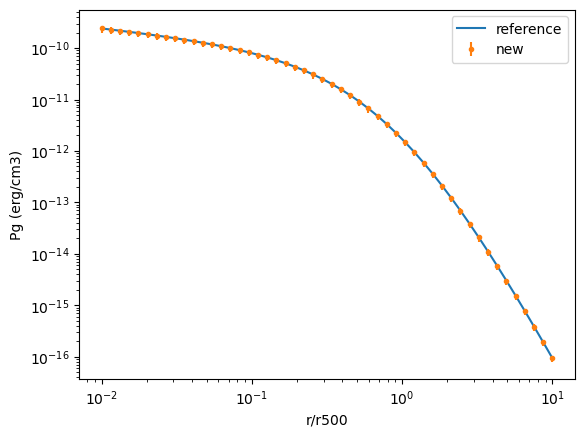

In [12]:
plt.loglog(xs, nfw_ref.Pg(xs), label='reference')
plt.errorbar(xs,
           [p.value for p in cls_err.Pg(xs)],
           yerr=[[p.plus for p in cls_err.Pg(xs)], [p.minus for p in cls_err.Pg(xs)]], fmt='o',markersize=3,
           label='new')

plt.legend()
plt.xlabel('r/r500')
plt.ylabel('Pg (erg/cm3)')

Text(0.5, 0, 'r (Mpc)')

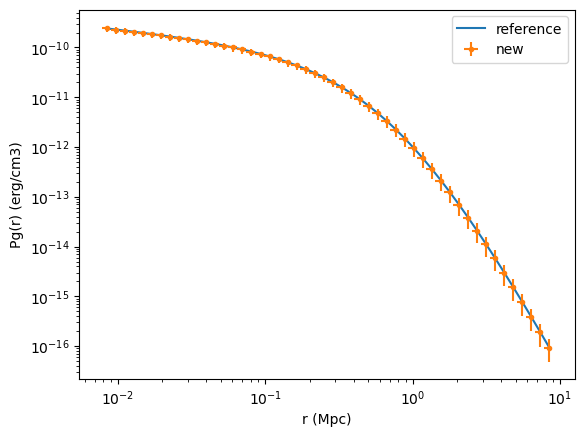

In [13]:
plt.loglog(rs_ref, nfw_ref.Pg_r(rs_ref), label='reference')
plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.Pg_r(rs_err)],
             yerr=[[p.plus for p in cls_err.Pg_r(rs_err)], [p.minus for p in cls_err.Pg_r(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')


plt.legend()
plt.ylabel('Pg(r) (erg/cm3)')
plt.xlabel('r (Mpc)')

In [14]:
cls_err.dP_dr(rs_err)

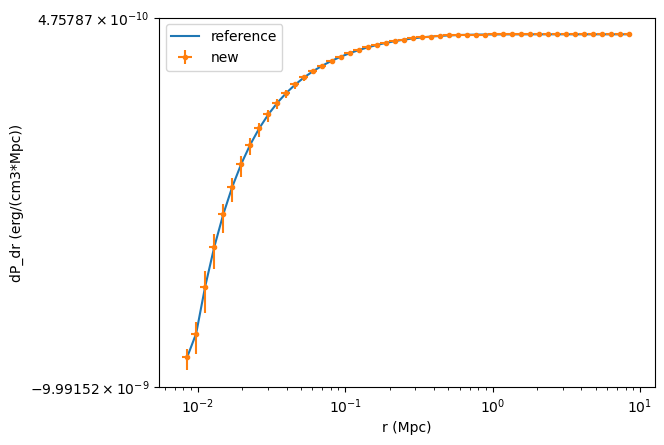

In [192]:
plt.plot(rs_ref, nfw_ref.dP_dr(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.dP_dr(rs_err)],
             yerr=[[p.plus for p in cls_err.dP_dr(rs_err)], [p.minus for p in cls_err.dP_dr(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')


plt.legend()
plt.ylabel('dP_dr (erg/(cm3*Mpc))')
plt.xlabel('r (Mpc)')
plt.xscale('log')
plt.yscale('symlog')

Text(0.5, 0, 'r (Mpc)')

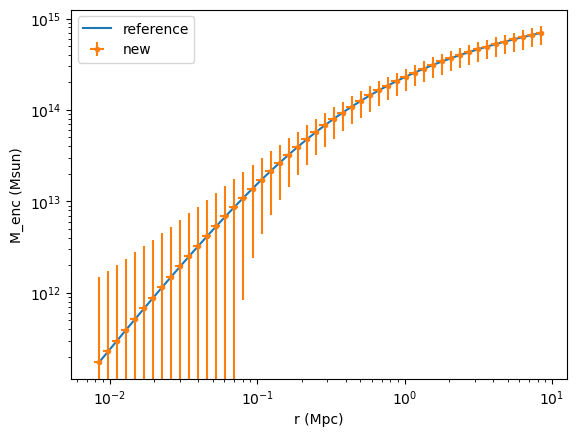

In [242]:
plt.loglog(rs_ref, nfw_ref.M_enc(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.M_enc(rs_err)],
             yerr=[[p.plus for p in cls_err.M_enc(rs_err)], [p.minus for p in cls_err.M_enc(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('M_enc (Msun)')
plt.xlabel('r (Mpc)')

In [240]:
[p for p in cls_err.M_enc(rs_err)][0]

0.0006666587643628444 ± 0.005037311713472843
0.0006666587643628444 ± 0.005037311713472843


Text(0.5, 0, 'r (Mpc)')

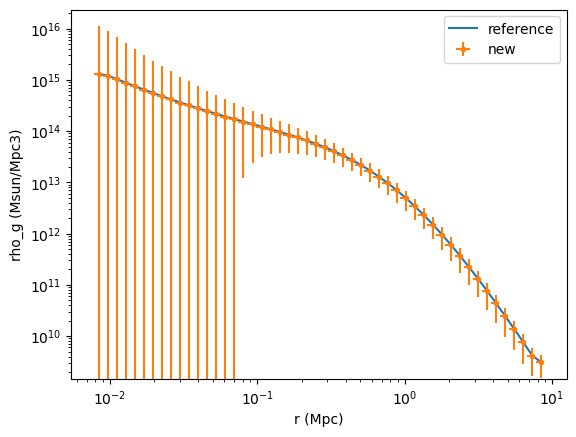

In [197]:
plt.loglog(rs_ref, nfw_ref.rho_g(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.rho_g(rs_err)],
             yerr=[[p.plus for p in cls_err.rho_g(rs_err)], [p.minus for p in cls_err.rho_g(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('rho_g (Msun/Mpc3)')
plt.xlabel('r (Mpc)')

In [227]:
print([p for p in cls_err.rho_g(rs_err)][0])

1296933941259036.5 (+9804570607743464.0, -9806489146155104.0)


In [18]:
from astropy import constants as const
const.G.to(u.Mpc**3 / (u.Msun*u.s**2))

<Quantity 4.51710305e-48 Mpc3 / (s2 solMass)>

In [19]:
const.G


<<class 'astropy.constants.codata2018.CODATA2018'> name='Gravitational constant' value=6.6743e-11 uncertainty=1.5e-15 unit='m3 / (kg s2)' reference='CODATA 2018'>

In [20]:
(u.erg/u.cm**3).to(u.Msun/u.Mpc**3)

1.6440094872954792e+19

Text(0.5, 0, 'r (Mpc)')

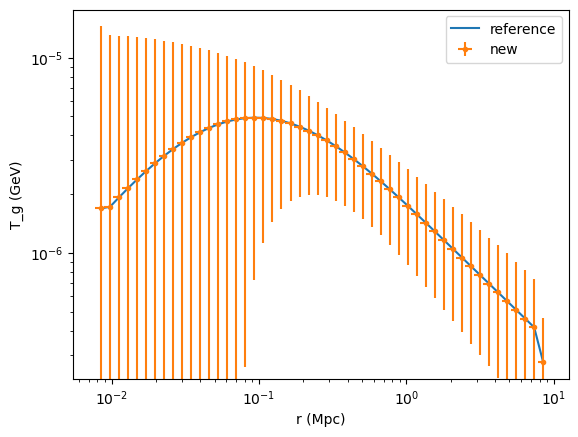

In [198]:
plt.loglog(rs_ref, nfw_ref.T_g([r.value for r in rs_ref]), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.T_g(rs_err)],
             yerr=[[p.plus for p in cls_err.T_g(rs_err)], [p.minus for p in cls_err.T_g(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('T_g (GeV)')
plt.xlabel('r (Mpc)')

In [224]:
print([p for p in cls_err.T_g(rs_err)][0])

1.6914273094078676e-06 ± 1.279257627538722e-05


Text(0.5, 0, 'r (Mpc)')

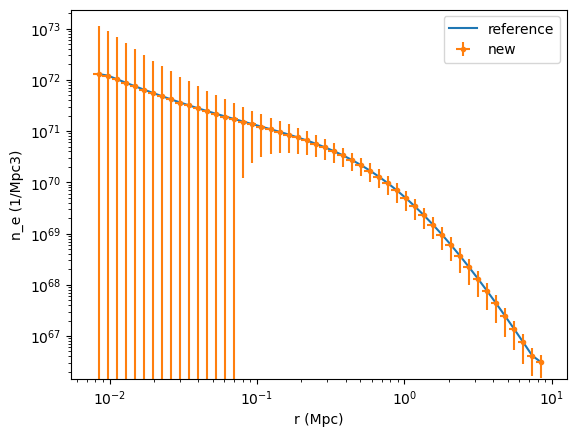

In [199]:
plt.loglog(rs_ref, nfw_ref.n_e(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.n_e(rs_err)],
             yerr=[[p.plus for p in cls_err.n_e(rs_err)], [p.minus for p in cls_err.n_e(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('n_e (1/Mpc3)')
plt.xlabel('r (Mpc)')

In [223]:
print([p for p in cls_err.n_e(rs_err)][0])

1.293636649927171e+72 (+9.779643720838035e+72, -9.781557381607205e+72)


Text(0.5, 0, 'r (Mpc)')

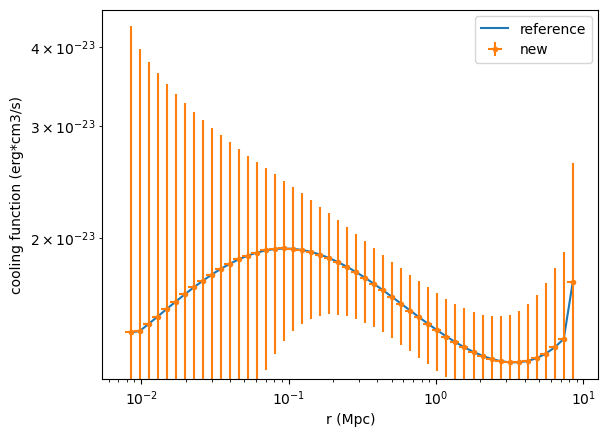

In [200]:
plt.loglog(rs_ref, nfw_ref.cooling_function(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.cooling_function(rs_err)],
             yerr=[[p.plus for p in cls_err.cooling_function(rs_err)], [p.minus for p in cls_err.cooling_function(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('cooling function (erg*cm3/s)')
plt.xlabel('r (Mpc)')

In [222]:
print([p for p in cls_err.cooling_function(rs_err)][2])

1.4634254499782413e-23 ± 2.324599198872708e-23


In [24]:
(u.GeV/u.keV).to(1)

999999.9999999999

Text(0.5, 0, 'r (Mpc)')

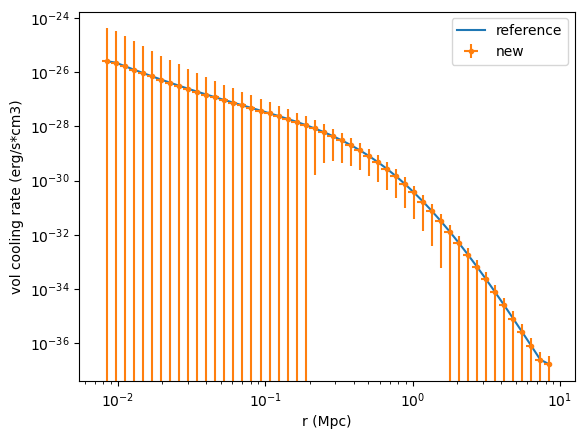

In [201]:
plt.loglog(rs_ref, nfw_ref.vol_cooling_rate(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.vol_cooling_rate(rs_err)],
             yerr=[[p.plus for p in cls_err.vol_cooling_rate(rs_err)], [p.minus for p in cls_err.vol_cooling_rate(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('vol cooling rate (erg/s*cm3)')
plt.xlabel('r (Mpc)')

In [26]:
(u.Mpc/u.cm).to(1)

3.085677581491367e+24

In [202]:
rmin = 0.0001

print(rs_ref[-1], nfw_ref.total_cooling_rate(rmin*nfw_ref.R500, rs_ref[-1]))
print(rs_ref[-10], nfw_ref.total_cooling_rate(rmin*nfw_ref.R500, rs_ref[-10]))

print(rs_err[-1], cls_err.total_cooling_rate(rmin*cls_err.R500, rs_err[-1]))
print(rs_err[-10], cls_err.total_cooling_rate(rmin*cls_err.R500, rs_err[-10]))

#plt.errorbar([r.value for r in rs_err],
#           [p.value for p in cls_err.vol_cooling_rate(rs_err)],
#             yerr=[[p.plus for p in cls_err.vol_cooling_rate(rs_err)], [p.minus for p in cls_err.vol_cooling_rate(rs_err)]],
#             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
#           label='new')

#plt.legend()
#plt.ylabel('vol cooling rate (erg/s)')
#plt.xlabel('r (Mpc)')

8.468364020893302 Mpc 9.305326419970404e+44 erg / s
2.3811080876998982 Mpc 9.06517777618844e+44 erg / s
8.468364020893329 (+0.7056970017411107, -0.42341820104466643) 9.30532641996943e+44 ± 1.443984183315868e+46
2.381108087699906 (+0.19842567397499214, -0.11905540438499528) 9.065177776187448e+44 ± 1.370773176234421e+46


Text(0.5, 0, 'r (Mpc)')

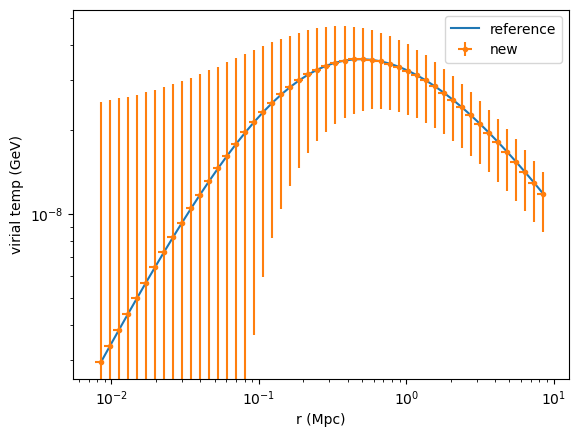

In [27]:
mchi = 0.01*u.GeV
plt.loglog(rs_ref, nfw_ref.virial_temperature(rs_ref, mchi), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.virial_temperature(rs_err, mchi)],
             yerr=[[p.plus for p in cls_err.virial_temperature(rs_err, mchi)], [p.minus for p in cls_err.virial_temperature(rs_err, mchi)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('virial temp (GeV)')
plt.xlabel('r (Mpc)')

In [28]:
(u.Msun/u.kg).to(1)

1.988409870698051e+30

Text(0.5, 0, 'r (Mpc)')

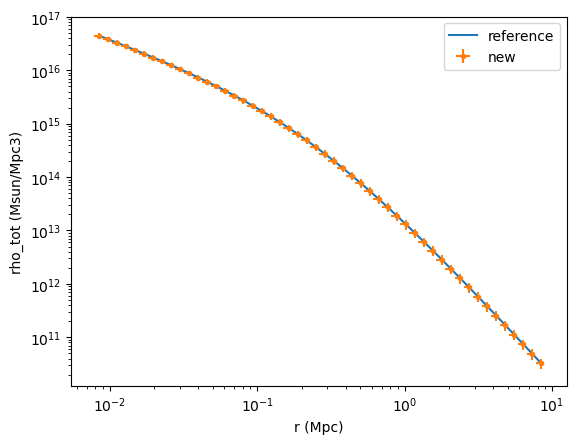

In [29]:
plt.loglog(rs_ref, nfw_ref.rho_tot(rs_ref), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.rho_tot(rs_err)],
             yerr=[[p.plus for p in cls_err.rho_tot(rs_err)], [p.minus for p in cls_err.rho_tot(rs_err)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('rho_tot (Msun/Mpc3)')
plt.xlabel('r (Mpc)')

Text(0.5, 0, 'r (Mpc)')

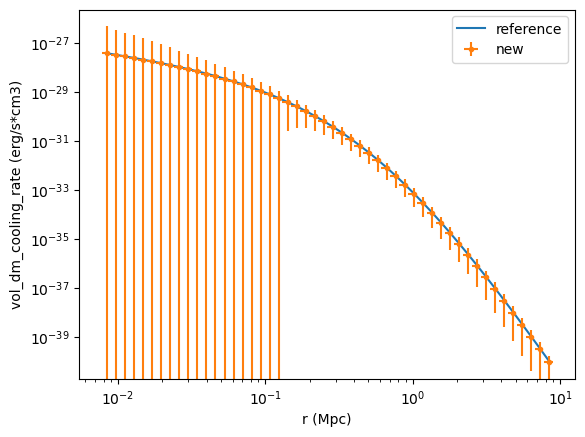

In [44]:
s0 = 1e-27*u.cm**2
mchi = 0.01*u.GeV

plt.loglog(rs_ref, nfw_ref.vol_dm_cooling_rate(rs_ref, s0, mchi), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)],
             yerr=[[p.plus for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)], [p.minus for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.legend()
plt.ylabel('vol_dm_cooling_rate (erg/s*cm3)')
plt.xlabel('r (Mpc)')

In [208]:
[print(p) for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)]

3.9177018321122816e-28 ± 4.387371642095914e-27
3.2592407679001975e-28 ± 3.173704137733966e-27
2.8140539965584996e-28 ± 2.3857295527043672e-27
2.418287313156138e-28 ± 1.785674995480287e-27
2.0671747528066245e-28 ± 1.3301548768188117e-27
1.7564965819514646e-28 ± 9.855364568693697e-28
1.4825068898824142e-28 ± 7.258503918378223e-28
1.2418650920329318e-28 ± 5.310567681902653e-28
1.031571238325371e-28 ± 3.8570348341068023e-28
8.489054991258617e-29 ± 2.778884440441214e-28
6.913726710641651e-29 ± 1.9845691635752919e-28
5.566529341095166e-29 ± 1.4038075247585337e-28
4.425603187732969e-29 ± 9.82781478864061e-29
3.470103337943794e-29 ± 6.80418582919779e-29
2.6799791255853694e-29 ± 4.655102752474866e-29
2.0358625758282625e-29 ± 3.1447422282376134e-29
1.5190634725968343e-29 ± 2.096128822033967e-29
1.1116591999436125e-29 ± 1.377550051098124e-29
7.966580827809323e-30 ± 8.919377875704322e-30
5.5820715756075375e-30 ± 5.6856112481879884e-30
3.818106075061013e-30 ± 3.565342883685236e-30
2.545245976964608

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [31]:
(u.Mpc/u.cm).to(1)

3.085677581491367e+24

In [32]:
(u.GeV/u.erg).to(1)

0.0016021766339999997

In [42]:
(u.Msun/u.Mpc**3).to(u.erg/u.cm**3)

6.082689958469012e-20

In [67]:
[print(r) for r in rs_err]
print(rs_ref[0], rs_ref[-1])

0.00846836402089333 (+0.0007056970017411108, -0.00042341820104466643)
0.009750435373478196 (+0.000812536281123183, -0.00048752176867390977)
0.01122660643045264 (+0.0009355505358710533, -0.0005613303215226319)
0.012926262994071881 (+0.0010771885828393234, -0.0006463131497035941)
0.014883239741858076 (+0.0012402699784881729, -0.0007441619870929037)
0.017136493765847933 (+0.0014280411471539944, -0.0008568246882923966)
0.019730880082583648 (+0.0016442400068819706, -0.0009865440041291822)
0.02271804455174865 (+0.0018931703793123875, -0.0011359022275874325)
0.026157451978576662 (+0.0021797876648813885, -0.001307872598928833)
0.03011756986623563 (+0.0025097974888529688, -0.0015058784933117814)
0.03467723138287656 (+0.0028897692819063797, -0.001733861569143828)
0.039927204675622774 (+0.0033272670563018977, -0.0019963602337811385)
0.045971999771477465 (+0.0038309999809564553, -0.002298599988573873)
0.052931949034715646 (+0.00441099575289297, -0.002646597451735782)
0.06094560259595358 (+0.005078

In [278]:
s0 = 1e-27*u.cm**2
mchi = 0.01*u.GeV
print(cls_err.integrated_dm_cooling_rate(rs_err[0], rs_err[-1], s0, mchi))

9.013093429607071e+42 (+2.0976428374289315e+42, -2.0227789189509155e+42)


In [276]:
(u.GeV/(u.cm**3 * u.s)).to(u.erg/(u.cm**3 * u.s))

0.0016021766339999997

In [277]:
u.GeV.to(u.erg)

0.0016021766339999997

In [294]:
print(cls_err.integrated_dm_cooling_rate_fast(s0, mchi))

8.894404328005631e+42 (+2.2048939401554783e+42, -2.1278297583320158e+42)


In [295]:
nfw_ref.integrated_dm_cooling_rate_fast(
    0.0001*nfw_ref.R500, 
    nfw_ref.R500, s0, mchi)

<Quantity 8.95607312e+42 erg / s>

In [204]:
nfw_ref.integrated_dm_cooling_rate(rs_ref[0], rs_ref[-1], s0, mchi)

<Quantity 9.01309343e+42 erg / s>

In [209]:
print(cls_err.total_cooling_rate(rs_err[0], rs_err[-1], n=50))

8.17425249594672e+44 (+1.804131340426158e+44, -1.7295074819141355e+44)


In [210]:
nfw_ref.total_cooling_rate(rs_ref[0], rs_ref[-1], n=50)

<Quantity 8.1742525e+44 erg / s>

In [99]:
nfw_ref.q(0.015*nfw_ref.R500, rc=0.1*nfw_ref.R500)

<Quantity -0.00239038 erg(1/4) / cm(3/4)>

In [115]:
cls_err.q(0.015*cls_err.R500, rc=0.1*cls_err.R500)

In [100]:
nfw_ref.get_Linj_from_L500()

<Quantity 3.16227766e+44 erg / s>

In [101]:
cls_err.get_Linj_from_L500()

<Quantity 3.16227766e+44 erg / s>

In [135]:
cls_err.h(cls_err.get_Linj_from_L500(), rs_err, 0.015*cls_err.R500,
        0.1*cls_err.R500,
        cls_err.q(0.015*cls_err.R500, rc=0.1*cls_err.R500)).value

AttributeError: 'numpy.ndarray' object has no attribute 'plus'

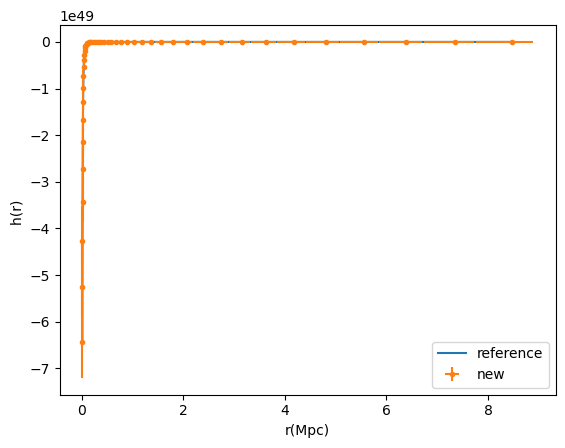

In [137]:
plt.plot(
    rs_ref, 
    nfw_ref.h(
        nfw_ref.get_Linj_from_L500(), 
        rs_ref, 
        0.015*nfw_ref.R500,
        0.1*nfw_ref.R500,
        nfw_ref.q(0.015*nfw_ref.R500, rc=0.1*nfw_ref.R500)), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.h(cls_err.get_Linj_from_L500(), rs_err, 0.015*cls_err.R500,
        0.1*cls_err.R500,
        cls_err.q(0.015*cls_err.R500, rc=0.1*cls_err.R500))],
             yerr=[[p.plus for p in cls_err.h(cls_err.get_Linj_from_L500(), rs_err, 0.015*cls_err.R500,
        0.1*cls_err.R500,
        cls_err.q(0.015*cls_err.R500, rc=0.1*cls_err.R500)).value], 
                   [p.minus for p in cls_err.h(cls_err.get_Linj_from_L500(), rs_err, 0.015*cls_err.R500,
        0.1*cls_err.R500,
        cls_err.q(0.015*cls_err.R500, rc=0.1*cls_err.R500)).value]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.xlabel('r(Mpc)')
plt.ylabel('h(r) ')
plt.legend()


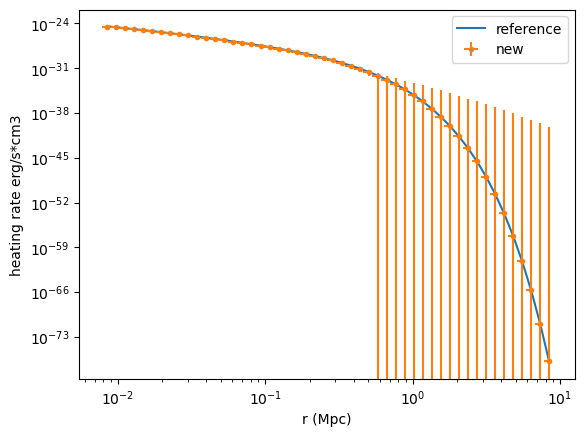

In [144]:
plt.loglog(rs_ref, 
    nfw_ref.vol_heating_rate(rs_ref, 0.1*nfw_ref.R500), label='reference')

plt.errorbar([r.value for r in rs_err],
           [p.value for p in cls_err.vol_heating_rate(rs_err, 
        0.1*cls_err.R500,)],
             yerr=[[p.plus for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)], [p.minus for p in cls_err.vol_dm_cooling_rate(rs_err, s0, mchi)]],
             xerr= [[r.plus for r in rs_err], [r.minus for r in rs_err]],fmt='o',markersize=3,
           label='new')

plt.ylabel('heating rate erg/s*cm3')
plt.xlabel('r (Mpc)')
plt.legend()

In [145]:
nfw_ref.total_heating_rate(0.001*nfw_ref.R500, nfw_ref.R500, 0.1*nfw_ref.R500)

<Quantity 4.42849832e+44 erg / s>

In [151]:
print(cls_err.total_heating_rate(0.001*cls_err.R500, cls_err.R500, 0.1*cls_err.R500))

INSIDE TOTAL HEATING RATE
4.441785910379421e+44 (+5.799184808845573e+43, -5.481626612887982e+43) erg / s


In [206]:
nfw_ref.L500_analytic(-27, -2, mult_agn=10)

<Quantity 9.14094063e+41 erg / s>

In [207]:
print(cls_err.L500_analytic(-27, -2, mult_agn=10))

1.064022428832104e+42 ± 4.462487242997259e+43


In [181]:
nfw_ref.agn_factors

<Quantity 1.44268117 erg / s>

In [182]:
print(cls_err.agn_factors)

1.4570864367346805 (+0.16619660849808968, -0.1551315260413761) erg / s


In [177]:
nfw_ref.tot_rad

<Quantity 7.57313979e+44 erg / s>

In [179]:
print(cls_err.tot_rad)

8.10940893816853e+44 ± 1.306552054661389e+46


In [218]:
print(cls_err.vol_cooling_rate(np.multiply([0.0001, 0.001, 0.01, 0.1, 1],cls_err.R500))[-1])

6.442632388922039e-28 ± 2.3563727346152594e-27


In [255]:
(u.Msun/u.Mpc**3).to(u.GeV/u.cm**3, equivalencies=u.mass_energy())

3.796516457291571e-17

In [252]:
xs_ext = np.logspace(-4,1)
rs_ref_ext = xs*nfw_ref.R500
rs_err_ext = xs*cls_err.R500

<ErrorbarContainer object of 3 artists>

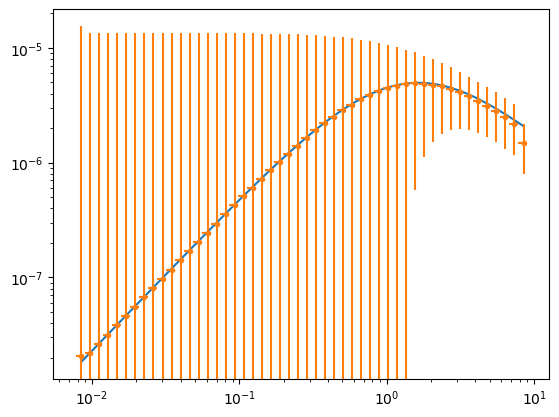

In [254]:
plt.loglog(rs_ref_ext, 
    nfw_ref.Tbs, label='reference')

plt.errorbar([r.value for r in rs_err_ext],
           [d.value for d in cls_err.Tbs],
             yerr=[[d.plus for d in cls_err.Tbs],
                   [d.minus for d in cls_err.Tbs]],
             xerr= [[r.plus for r in rs_err_ext],
                    [r.minus for r in rs_err_ext]],fmt='o',markersize=3,
           label='new')

<ErrorbarContainer object of 3 artists>

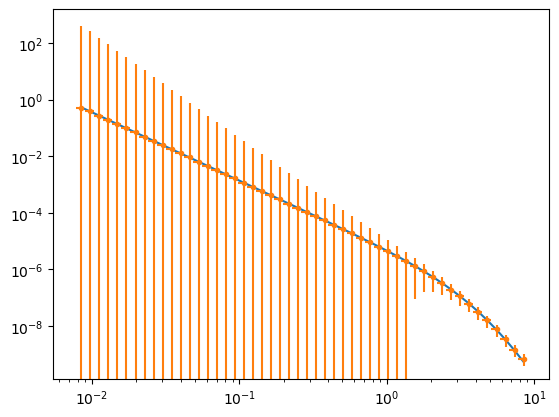

In [257]:
plt.loglog(rs_ref_ext, 
    nfw_ref.dm_rdep_factors, label='reference')

plt.errorbar([r.value for r in rs_err_ext],
           [d.value for d in cls_err.dm_rdep_factors],
             yerr=[[d.plus for d in cls_err.dm_rdep_factors],
                   [d.minus for d in cls_err.dm_rdep_factors]],
             xerr= [[r.plus for r in rs_err_ext],
                    [r.minus for r in rs_err_ext]],fmt='o',markersize=3,
           label='new')
